# XGB Boost

## Importing the libraries

In [1]:
import numpy as np 
import pandas as pd 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import xgboost as xgb

## Importing the dataset

In [2]:
data = pd.read_csv('./clinvar_conflicting.csv')

C:\Users\Sarvesh Ram Kumar\AppData\Local\Temp\ipykernel_3084\4122730503.py:1: DtypeWarning: Columns (0,38,40) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('./clinvar_conflicting.csv')


In [3]:
data.describe()

,POS,AF_ESP,AF_EXAC,AF_TGP,ORIGIN,SSR,CLASS,DISTANCE,STRAND,MOTIF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
count,6.518800e+04,65188.000000,65188.000000,65188.000000,65188.000000,130.000000,65188.000000,108.000000,65174.000000,2.0,2.000000,60975.000000,64096.000000,64096.000000,25593.000000
mean,7.757594e+07,0.014511,0.014492,0.015263,1.342486,2.269231,0.252102,825.731481,-0.006659,1.0,-0.080000,0.345058,15.685616,2.554131,-0.402258
std,5.974051e+07,0.057795,0.059542,0.059527,5.688772,4.190777,0.434223,1069.363315,0.999985,0.0,0.024042,0.361238,10.836350,2.961553,1.872684
min,9.610000e+02,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,-1.000000,1.0,-0.097000,0.000069,0.001000,-5.477391,-3.000000
25%,3.254179e+07,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,55.500000,-1.000000,1.0,-0.088500,0.024300,7.141000,0.462951,-2.000000
50%,5.797021e+07,0.000000,0.000040,0.000000,1.000000,1.000000,0.000000,469.000000,-1.000000,1.0,-0.080000,0.157000,14.090000,1.642948,-1.000000
75%,1.127454e+08,0.001200,0.001230,0.001600,1.000000,1.000000,1.000000,1415.000000,1.000000,1.0,-0.071500,0.710000,24.100000,4.381392,1.000000
max,2.476080e+08,0.499000,0.499890,0.499800,513.000000,16.000000,1.000000,4759.000000,1.000000,1.0,-0.063000,1.000000,99.000000,46.556261,3.000000


In [4]:
num_cols = data.select_dtypes(include=['float64', 'int64']).columns
cat_cols = data.select_dtypes(include=['object']).columns

data[num_cols] = data[num_cols].fillna(data[num_cols].median())

data[cat_cols] = data[cat_cols].fillna('Unknown')

In [5]:
data['CLASS'].value_counts()

CLASS
0    48754
1    16434
Name: count, dtype: int64

In [6]:
data['CHROM'].value_counts()

CHROM
2     8166
17    4918
11    4719
1     4454
5     3643
16    3586
19    3513
7     2867
9     2744
13    2515
12    2447
10    2341
6     2159
X     1926
8     1852
14    1755
3     1579
15    1557
4     1206
22    1043
3      950
18     785
21     724
20     682
2      479
17     476
19     398
16     341
12     303
14     219
15     168
13     131
11     127
21     119
18     111
22      92
20      77
MT      16
Name: count, dtype: int64

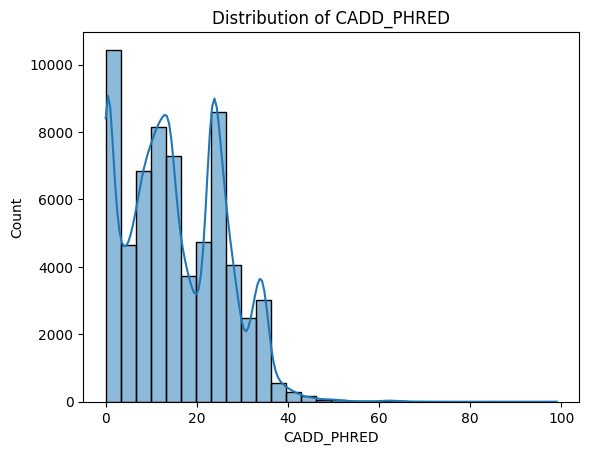

In [7]:
sns.histplot(data['CADD_PHRED'], bins=30, kde=True)
plt.title("Distribution of CADD_PHRED")
plt.show()


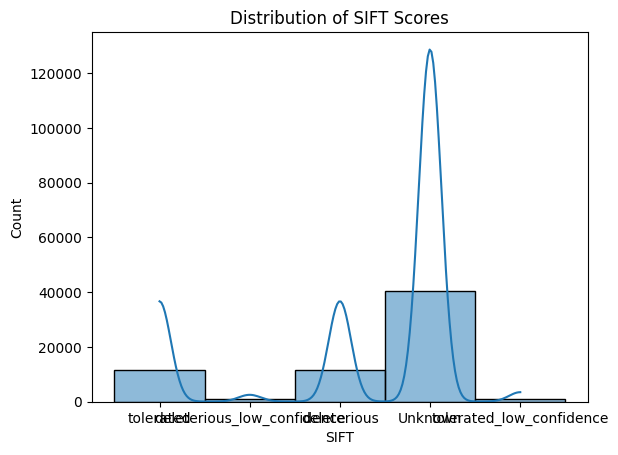

In [8]:
sns.histplot(data['SIFT'], bins=30, kde=True)
plt.title("Distribution of SIFT Scores")
plt.show()

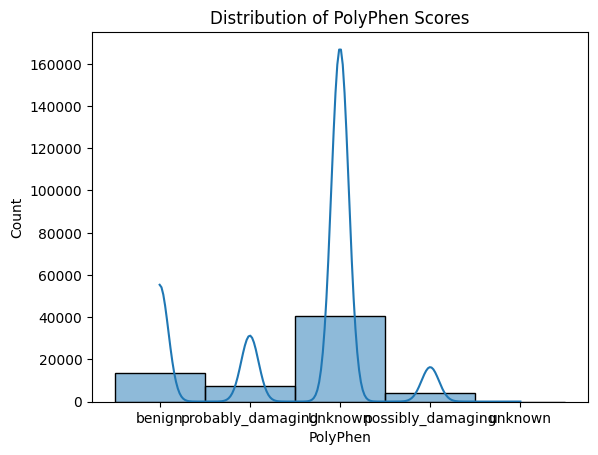

In [9]:
sns.histplot(data['PolyPhen'], bins=30, kde=True)
plt.title("Distribution of PolyPhen Scores")
plt.show()

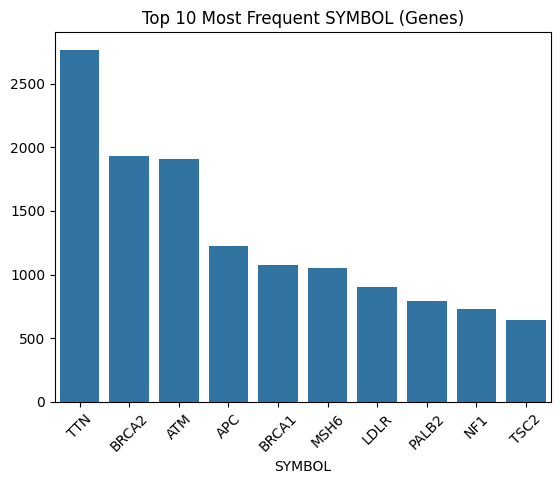

In [10]:
top_genes = data['SYMBOL'].value_counts().nlargest(10)
sns.barplot(x=top_genes.index, y=top_genes.values)
plt.title("Top 10 Most Frequent SYMBOL (Genes)")
plt.xticks(rotation=45)
plt.show()

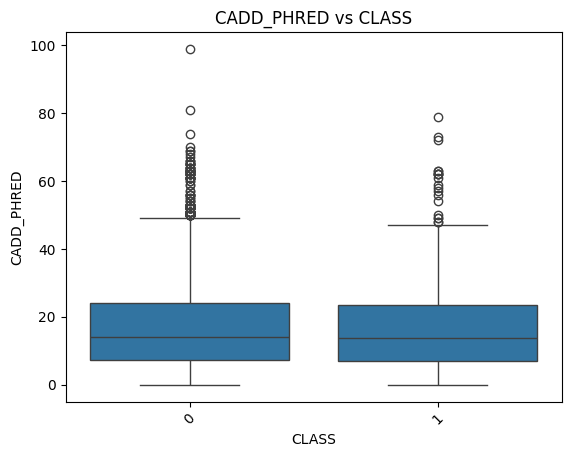

In [11]:
sns.boxplot(x='CLASS', y='CADD_PHRED', data=data)
plt.title("CADD_PHRED vs CLASS")
plt.xticks(rotation=45)
plt.show()

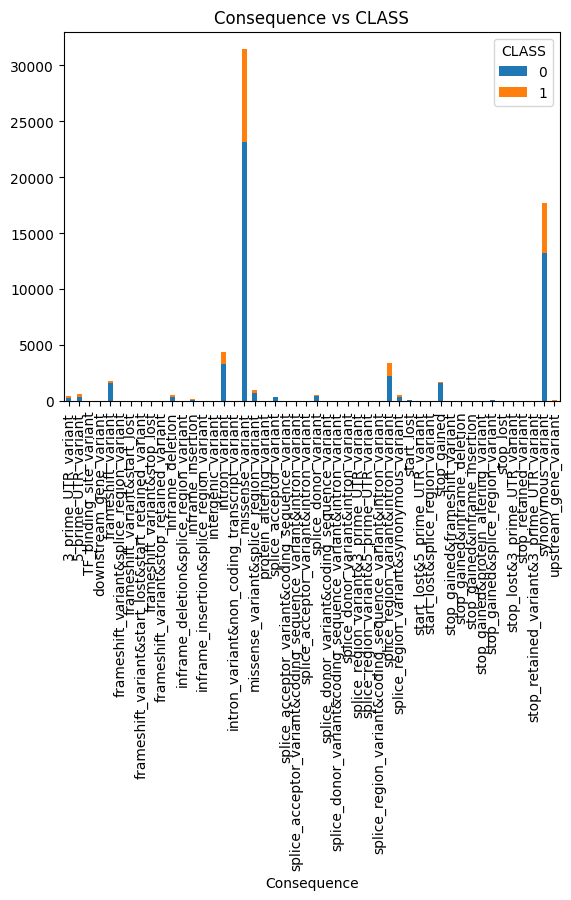

In [12]:
consequence_class = pd.crosstab(data['Consequence'], data['CLASS'])
consequence_class.plot(kind='bar', stacked=True)
plt.title("Consequence vs CLASS")
plt.xticks(rotation=90)
plt.show()

## Data Prepocessing

In [13]:
X = data.drop(['CLASS'], axis=1)
y = data['CLASS']

In [14]:
label_encoder = LabelEncoder()
for column in X.select_dtypes(include=['object']).columns:
    X[column] = X[column].astype(str)  
    X[column] = label_encoder.fit_transform(X[column])

## Splitting the dataset into the Training set and Test set

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## Feature Scaling

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training the XGB Boost model on the Training set

In [17]:
xgb = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb.fit(X_train_scaled, y_train)


c:\Users\Sarvesh Ram Kumar\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:158: UserWarning: [20:14:30] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

## Predicting the Test set results

In [18]:
y_pred = xgb.predict(X_test_scaled)


## Analysis

In [19]:
accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 79.75%


In [20]:
class_report = classification_report(y_test, y_pred)
print('Classification Report:')
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87     14615
           1       0.65      0.43      0.52      4942

    accuracy                           0.80     19557
   macro avg       0.74      0.68      0.69     19557
weighted avg       0.78      0.80      0.78     19557

